# Student Dropout Prediction — notebook

*Muhammad Elias Muhammadi · ML Zoomcamp midterm project*

In this notebook I go through the whole process I followed: loading and cleaning the data, exploring it,
checking which features actually matter, and then training and tuning a few different models before picking
the final one. The final training logic lives in `train.py`; this notebook is where I made the decisions.

**The question:** given what a university knows about a student by the end of their first year
(background, admission info, tuition status and first-year academic results), how likely is that student to drop out?

Dataset: [Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)
(UCI, Realinho et al., 2021). 4,424 students from a Portuguese higher-education institution.

In [1]:
import os

# Keep each worker single-threaded; parallelism comes from cross-validation jobs instead.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             mutual_info_score, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from features import (CATEGORICAL, ENGINEERED, NUMERICAL, TARGET,
                      add_engineered_features, load_data, to_records)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
N_JOBS = min(8, os.cpu_count() or 1)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

## 1. Loading and cleaning the data

The raw CSV is separated by `;`. Two small annoyances in the header: one column name ends with a tab character
(`"Daytime/evening attendance\t"`) and nationality is spelled `Nacionality`. I fixed both by mapping every
column to a clean snake_case name inside `features.py`, so the notebook, the training script and the API all
use the same names.

The original target has three classes: `Dropout`, `Enrolled` and `Graduate`. What a university actually wants
to know is *who is at risk of leaving*, so I turned it into a binary target: `dropout = 1` if the student
dropped out, `0` otherwise.

In [2]:
df = load_data()
print(df.shape)
df.head()

(4424, 38)


,marital_status,application_mode,application_order,course,daytime_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,special_needs,debtor,tuition_up_to_date,gender,scholarship_holder,age_at_enrollment,international,sem1_credited,sem1_enrolled,sem1_evaluations,sem1_approved,sem1_grade,sem1_without_evaluations,sem2_credited,sem2_enrolled,sem2_evaluations,sem2_approved,sem2_grade,sem2_without_evaluations,unemployment_rate,inflation_rate,gdp,target,dropout
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,0
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,0
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,0


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.value_counts()

Missing values: 0
Duplicate rows: 0


int64      30
float64     7
object      1
Name: count, dtype: int64

No missing values and no duplicates, which is nice. Everything is numeric, but that's misleading: columns like
`course`, `nationality` or `mothers_occupation` are **integer codes for categories**, not real numbers.
Course `9500` is not "bigger" than course `33`. So those 9 columns are treated as categorical and one-hot encoded.

In [4]:
df[CATEGORICAL].nunique().sort_values(ascending=False)

fathers_occupation        46
fathers_qualification     34
mothers_occupation        32
mothers_qualification     29
nationality               21
application_mode          18
previous_qualification    17
course                    17
marital_status             6
dtype: int64

## 2. Exploratory data analysis

### 2.1 Target variable

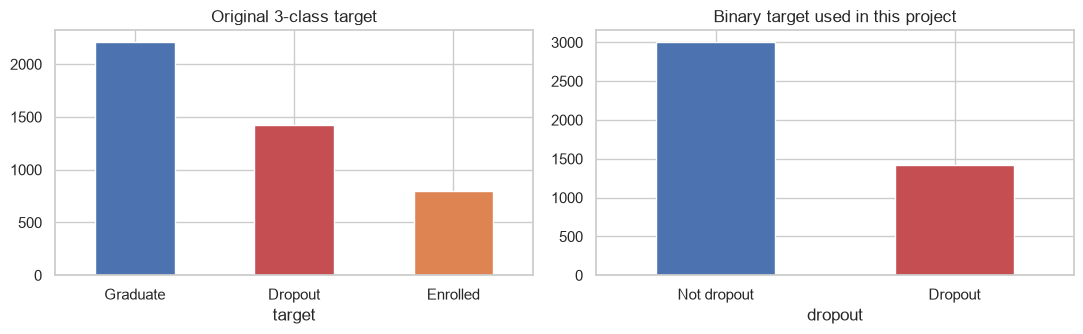

dropout
0    0.679
1    0.321
Name: proportion, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["target"].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52", "#DD8452"])
axes[0].set_title("Original 3-class target")
axes[0].tick_params(axis="x", rotation=0)
df[TARGET].map({0: "Not dropout", 1: "Dropout"}).value_counts().plot.bar(ax=axes[1], color=["#4C72B0", "#C44E52"])
axes[1].set_title("Binary target used in this project")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

df[TARGET].value_counts(normalize=True).round(3)

About **32% of students drop out**. That's moderately imbalanced: not extreme, but enough that plain accuracy
would be a misleading metric (a model that says "nobody drops out" is already 68% accurate). I use **ROC AUC**
as the main metric for comparing models and later look at precision, recall and F1 when choosing a decision threshold.

### 2.2 Numerical features: ranges and distributions

In [6]:
df[NUMERICAL].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
application_order,1.73,1.31,0.00,1.00,9.00
daytime_attendance,0.89,0.31,0.00,1.00,1.00
previous_qualification_grade,132.61,13.19,95.00,133.10,190.00
admission_grade,126.98,14.48,95.00,126.10,190.00
displaced,0.55,0.50,0.00,1.00,1.00
special_needs,0.01,0.11,0.00,0.00,1.00
debtor,0.11,0.32,0.00,0.00,1.00
tuition_up_to_date,0.88,0.32,0.00,1.00,1.00
gender,0.35,0.48,0.00,0.00,1.00
scholarship_holder,0.25,0.43,0.00,0.00,1.00


A few things stand out:

- `age_at_enrollment` goes from 17 up to 70, so most students are young but there's a long tail of mature students.
- Many semester columns have a minimum of 0. A student with `sem1_enrolled > 0` but `sem1_approved = 0` passed
  nothing in the first semester, which I expect to be a strong dropout signal.
- `sem1_grade` / `sem2_grade` are on a 0–20 scale (Portuguese system); a grade of 0 means no graded units.
- `unemployment_rate`, `inflation_rate` and `gdp` are macro-economic values for the year the student enrolled,
  so they only take a handful of distinct values.

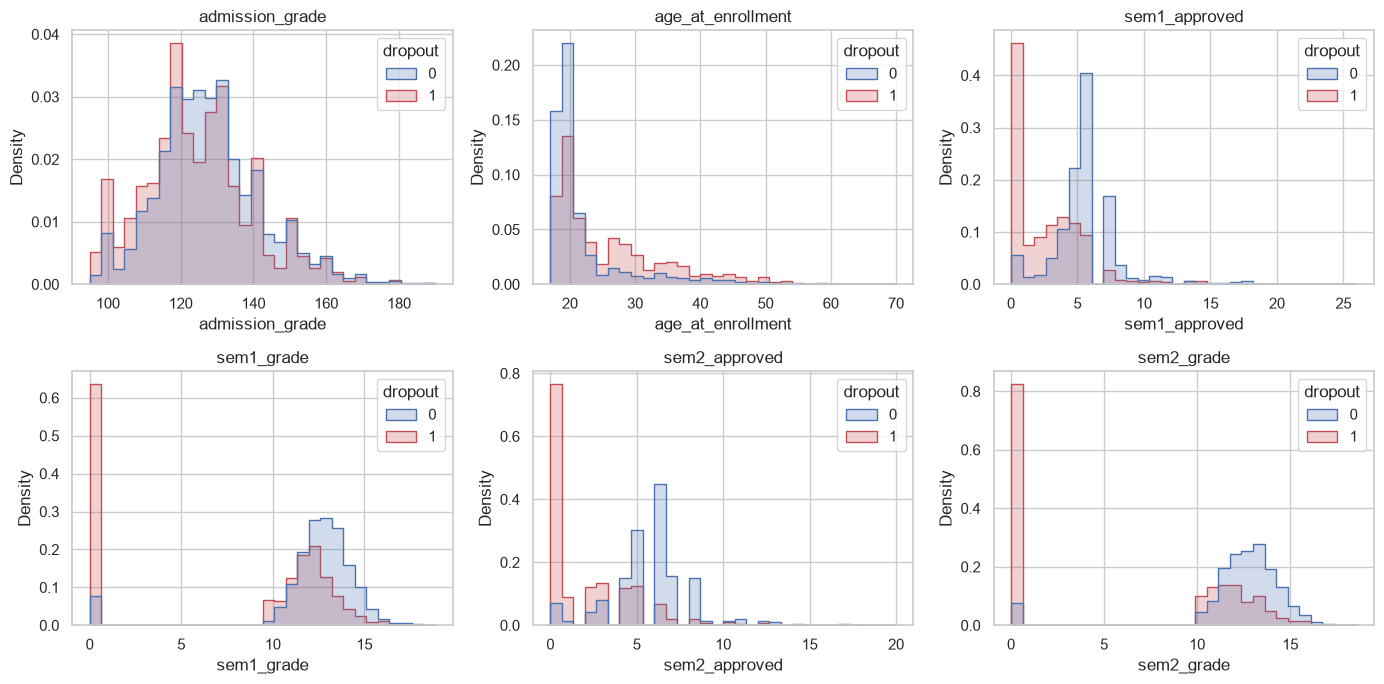

In [7]:
plot_cols = ["admission_grade", "age_at_enrollment", "sem1_approved", "sem1_grade", "sem2_approved", "sem2_grade"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat="density", common_norm=False,
                 element="step", palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

The difference is very clear for the first-year academic results. Dropouts pile up at **0 approved units and
a grade of 0**, especially in the second semester. Admission grade overlaps a lot between the two groups, so how a
student *entered* the university matters much less than how their first year actually went.
Older students also drop out more often.

### 2.3 Dropout rate across binary and categorical features

In [8]:
global_rate = df[TARGET].mean()
flags = ["tuition_up_to_date", "debtor", "scholarship_holder", "gender", "displaced", "daytime_attendance", "international"]

rows = []
for col in flags:
    for value, rate in df.groupby(col)[TARGET].mean().items():
        rows.append({"feature": col, "value": value, "dropout_rate": rate,
                     "count": int((df[col] == value).sum()), "risk_ratio": rate / global_rate})
pd.DataFrame(rows).round(3)

,feature,value,dropout_rate,count,risk_ratio
0,tuition_up_to_date,0,0.866,528,2.695
1,tuition_up_to_date,1,0.247,3896,0.770
2,debtor,0,0.283,3921,0.881
3,debtor,1,0.620,503,1.931
4,scholarship_holder,0,0.387,3325,1.205
5,scholarship_holder,1,0.122,1099,0.380
6,gender,0,0.251,2868,0.782
7,gender,1,0.451,1556,1.403
8,displaced,0,0.376,1998,1.172
9,displaced,1,0.276,2426,0.859


This table already tells a story:

- Students whose **tuition fees are not up to date** drop out at a much higher rate than average — the biggest single effect here.
- **Debtors** are also far more likely to leave.
- **Scholarship holders** drop out much less.
- `gender = 1` (male in the dataset documentation) shows a higher dropout rate than `gender = 0`.
- `international` barely moves the rate; it's also a small group.

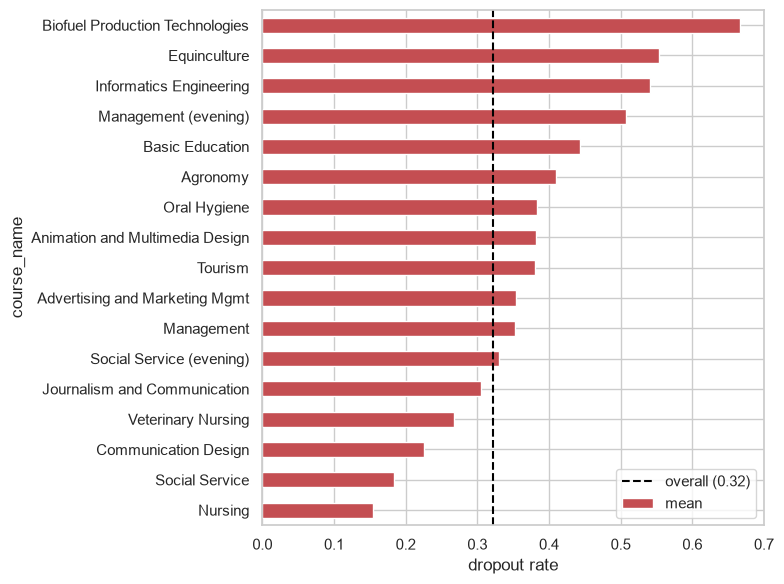

,mean,count
course_name,,
Nursing,0.154,766
Social Service,0.183,355
Communication Design,0.226,226
Veterinary Nursing,0.267,337
Journalism and Communication,0.305,331
Social Service (evening),0.330,215
Management,0.353,380
Advertising and Marketing Mgmt,0.354,268
Tourism,0.381,252


In [9]:
course_names = {
    33: "Biofuel Production Technologies", 171: "Animation and Multimedia Design",
    8014: "Social Service (evening)", 9003: "Agronomy", 9070: "Communication Design",
    9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture",
    9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
    9556: "Oral Hygiene", 9670: "Advertising and Marketing Mgmt", 9773: "Journalism and Communication",
    9853: "Basic Education", 9991: "Management (evening)",
}
by_course = (df.assign(course_name=df["course"].map(course_names))
               .groupby("course_name")[TARGET].agg(["mean", "count"])
               .sort_values("mean"))
ax = by_course["mean"].plot.barh(figsize=(8, 6), color="#C44E52")
ax.axvline(global_rate, color="black", linestyle="--", label=f"overall ({global_rate:.2f})")
ax.set_xlabel("dropout rate")
ax.legend()
plt.tight_layout()
plt.show()
by_course.round(3)

Dropout rates vary a lot by course: Nursing and Social Service are well below average, while some evening and
technology courses are much higher. Some courses have small counts (Biofuel Production Technologies has only a
handful of students), so I wouldn't read too much into those bars on their own.

### 2.4 Feature importance analysis

To rank features before modelling I used two simple, model-free measures:

- **Mutual information** between each categorical feature and the target.
- **Univariate ROC AUC** for each numerical feature, i.e. how well that one column alone separates dropouts from the rest.
  I report `max(auc, 1 - auc)` so features that are *negatively* related to dropout also show as important.

In [10]:
mi = (df[CATEGORICAL]
      .apply(lambda s: mutual_info_score(s, df[TARGET]))
      .sort_values(ascending=False))
mi.to_frame("mutual_info").round(4)

,mutual_info
application_mode,0.0444
course,0.0346
mothers_occupation,0.0237
previous_qualification,0.0217
fathers_qualification,0.0203
fathers_occupation,0.0202
mothers_qualification,0.0201
marital_status,0.0064
nationality,0.0026


In [11]:
df_fe = add_engineered_features(df)
auc_rows = []
for col in NUMERICAL + ENGINEERED:
    auc = roc_auc_score(df_fe[TARGET], df_fe[col])
    auc_rows.append({"feature": col, "auc": max(auc, 1 - auc),
                     "direction": "higher -> more dropout" if auc >= 0.5 else "higher -> less dropout"})
univariate_auc = pd.DataFrame(auc_rows).sort_values("auc", ascending=False).reset_index(drop=True)
univariate_auc.round(3).head(15)

,feature,auc,direction
0,sem2_approval_rate,0.874,higher -> less dropout
1,sem2_approved,0.855,higher -> less dropout
2,sem1_approval_rate,0.840,higher -> less dropout
3,sem1_approved,0.818,higher -> less dropout
4,sem2_grade,0.814,higher -> less dropout
5,sem1_grade,0.773,higher -> less dropout
6,age_at_enrollment,0.671,higher -> more dropout
7,tuition_up_to_date,0.649,higher -> less dropout
8,scholarship_holder,0.614,higher -> less dropout
9,sem2_enrolled,0.611,higher -> less dropout


The ranking confirms what the plots showed: **second-semester results** (approved units, grade and the approval
rate I engineered) are by far the strongest single signals, followed by the first semester, age and tuition status.
The macro-economic features sit at 0.51–0.54, so on their own they carry almost no information.
For the categorical columns, `application_mode` and `course` have the highest mutual information with the target.

**About the engineered features:** I added only three, keeping them easy to explain:

- `sem1_approval_rate` / `sem2_approval_rate` = approved units / enrolled units (0 if the student enrolled in nothing).
  Passing 5 out of 6 units is very different from passing 5 out of 12, and the raw counts hide that.
- `grade_change` = second-semester grade minus first-semester grade, to capture students who are slipping.

`sem2_approval_rate` comes out as the single best feature (AUC 0.874, better than the raw `sem2_approved` count at 0.855),
so the ratio clearly adds something. `grade_change` is weaker (0.574) but I kept it since it's cheap and easy to explain.

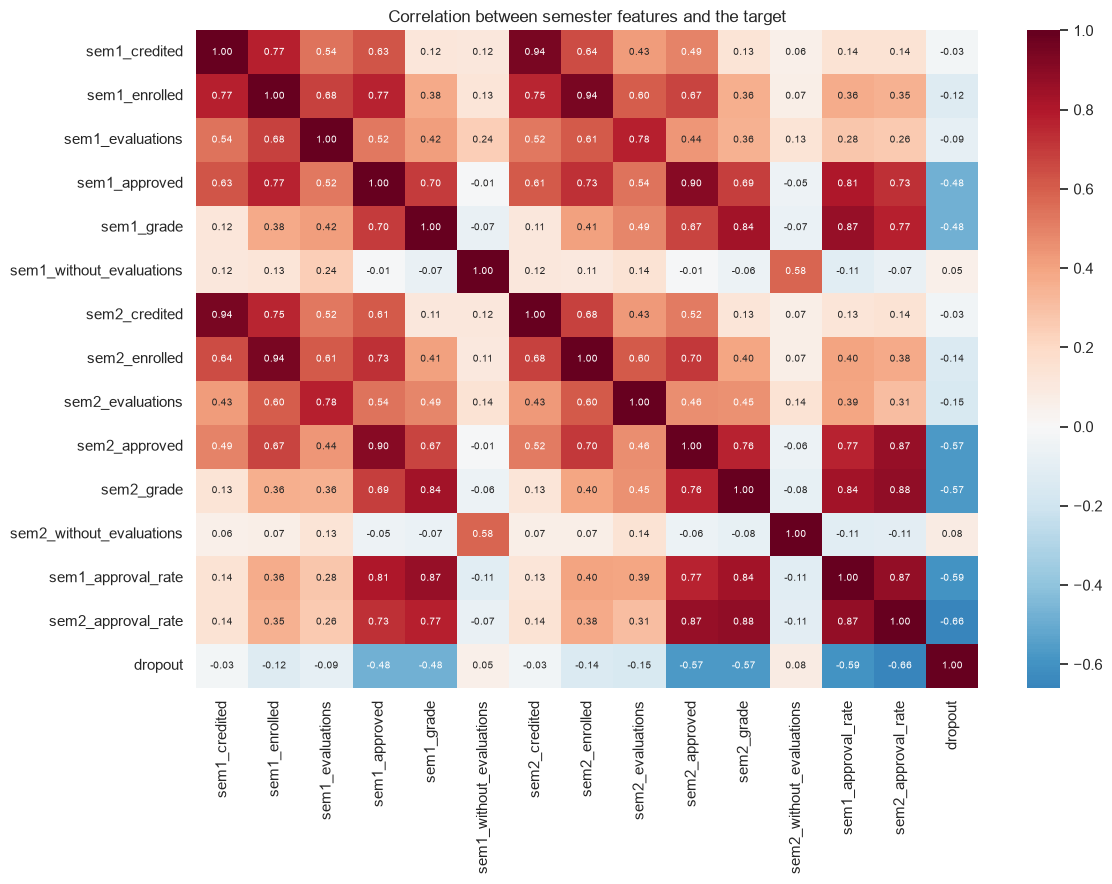

In [12]:
sem_cols = [c for c in df_fe.columns if c.startswith("sem")] + [TARGET]
plt.figure(figsize=(12, 9))
sns.heatmap(df_fe[sem_cols].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation between semester features and the target")
plt.tight_layout()
plt.show()

The semester features are strongly correlated with each other (for example `sem1_enrolled` and `sem2_enrolled`, or
first- and second-semester approved units). That's expected and not a problem for tree models. For logistic
regression I use L2 regularisation, which copes with correlated inputs reasonably well.

**A note on data leakage:** none of the features are derived from the target. The semester results are things the
university already knows at the end of the first year, which is exactly when I imagine this model being used.
The model is *not* meant for day-one predictions at enrolment, and I mention that limitation in the README.

## 3. Train / test split

I kept 20% of the data as a test set that I don't touch until the very end. All model selection and
hyperparameter tuning happens with **5-fold stratified cross-validation** on the remaining 80%.

In [13]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df[TARGET])
y_full_train = df_full_train[TARGET].values
y_test = df_test[TARGET].values
X_full_train = to_records(df_full_train)
X_test = to_records(df_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(len(X_full_train), len(X_test), y_full_train.mean().round(3), y_test.mean().round(3))

3539 885 0.321 0.321


Each model is a scikit-learn pipeline: `DictVectorizer` (one-hot encodes the categorical codes and passes numbers
through) followed by the model. Logistic regression also gets a `StandardScaler`, since it's sensitive to feature scale.

In [14]:
def make_model(estimator, scale=False):
    steps = [DictVectorizer(sparse=False)]
    if scale:
        steps.append(StandardScaler())
    steps.append(estimator)
    return make_pipeline(*steps)


def cv_auc(model):
    return cross_val_score(model, X_full_train, y_full_train, cv=cv, scoring="roc_auc", n_jobs=N_JOBS).mean()


def tune(model, grid):
    search = GridSearchCV(model, grid, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
    search.fit(X_full_train, y_full_train)
    return search

## 4. Model training and tuning

I trained four models, from simplest to most complex:

1. **Logistic regression** — linear baseline
2. **Decision tree**
3. **Random forest**
4. **XGBoost** (gradient boosted trees)

For each one I first look at the cross-validated AUC with default settings, then tune the most important
hyperparameters with a grid search.

### 4.1 Logistic regression

In [15]:
lr = make_model(LogisticRegression(max_iter=5000, random_state=SEED), scale=True)
lr_default = cv_auc(lr)
lr_search = tune(lr, {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]})

pd.DataFrame(lr_search.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]].round(4)

,param_logisticregression__C,mean_test_score,std_test_score
0,0.001,0.9098,0.0105
1,0.003,0.9167,0.0089
2,0.010,0.9186,0.0079
3,0.030,0.9179,0.0073
4,0.100,0.9159,0.0082
5,0.300,0.9142,0.0093
6,1.000,0.9115,0.0107
7,3.000,0.9087,0.0114


In [16]:
print(f"default AUC: {lr_default:.4f}  |  tuned AUC: {lr_search.best_score_:.4f}  |  best: {lr_search.best_params_}")

default AUC: 0.9115  |  tuned AUC: 0.9186  |  best: {'logisticregression__C': 0.01}


Smaller `C` means stronger regularisation. After one-hot encoding there are 238 columns, many of them rare categories,
so some regularisation helps: CV AUC goes from 0.912 with the default `C=1` to 0.919 with `C=0.01`.

### 4.2 Decision tree

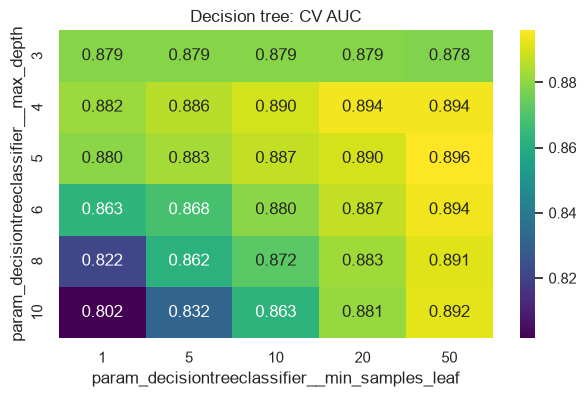

default AUC: 0.7850  |  tuned AUC: 0.8960  |  best: {'decisiontreeclassifier__max_depth': 5, 'decisiontreeclassifier__min_samples_leaf': 50}


In [17]:
dt = make_model(DecisionTreeClassifier(random_state=SEED))
dt_default = cv_auc(dt)
dt_search = tune(dt, {
    "decisiontreeclassifier__max_depth": [3, 4, 5, 6, 8, 10],
    "decisiontreeclassifier__min_samples_leaf": [1, 5, 10, 20, 50],
})

dt_scores = pd.DataFrame(dt_search.cv_results_).pivot(
    index="param_decisiontreeclassifier__max_depth",
    columns="param_decisiontreeclassifier__min_samples_leaf",
    values="mean_test_score")
plt.figure(figsize=(7, 4))
sns.heatmap(dt_scores, annot=True, fmt=".3f", cmap="viridis")
plt.title("Decision tree: CV AUC")
plt.show()
print(f"default AUC: {dt_default:.4f}  |  tuned AUC: {dt_search.best_score_:.4f}  |  best: {dt_search.best_params_}")

An unrestricted tree overfits badly (look at the default AUC). Limiting the depth and requiring more samples per leaf
improves it a lot, but a single tree still trails the linear model.

### 4.3 Random forest

In [18]:
rf = make_model(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1))
rf_default = cv_auc(rf)
rf_search = tune(rf, {
    "randomforestclassifier__max_depth": [10, 20, None],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__max_features": ["sqrt", 0.3],
})
rf_results = pd.DataFrame(rf_search.cv_results_)
cols = ["param_randomforestclassifier__max_depth", "param_randomforestclassifier__min_samples_leaf",
        "param_randomforestclassifier__max_features", "mean_test_score"]
print(f"default AUC: {rf_default:.4f}  |  tuned AUC: {rf_search.best_score_:.4f}  |  best: {rf_search.best_params_}")
rf_results[cols].sort_values("mean_test_score", ascending=False).head(8).round(4)

default AUC: 0.9171  |  tuned AUC: 0.9181  |  best: {'randomforestclassifier__max_depth': 20, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 1}


,param_randomforestclassifier__max_depth,param_randomforestclassifier__min_samples_leaf,param_randomforestclassifier__max_features,mean_test_score
6,20,1,sqrt,0.9181
17,None,5,0.3,0.9174
7,20,3,sqrt,0.9174
11,20,5,0.3,0.9174
12,None,1,sqrt,0.9171
16,None,3,0.3,0.9165
10,20,3,0.3,0.9165
13,None,3,sqrt,0.9164


### 4.4 XGBoost

In [19]:
xgb = make_model(XGBClassifier(eval_metric="auc", random_state=SEED, n_jobs=1))
xgb_default = cv_auc(xgb)
xgb_search = tune(xgb, {
    "xgbclassifier__n_estimators": [200, 400],
    "xgbclassifier__learning_rate": [0.03, 0.1],
    "xgbclassifier__max_depth": [3, 4, 6],
    "xgbclassifier__min_child_weight": [1, 5],
    "xgbclassifier__subsample": [0.8],
    "xgbclassifier__colsample_bytree": [0.8],
})
xgb_results = pd.DataFrame(xgb_search.cv_results_)
cols = ["param_xgbclassifier__n_estimators", "param_xgbclassifier__learning_rate",
        "param_xgbclassifier__max_depth", "param_xgbclassifier__min_child_weight", "mean_test_score"]
print(f"default AUC: {xgb_default:.4f}  |  tuned AUC: {xgb_search.best_score_:.4f}  |  best: {xgb_search.best_params_}")
xgb_results[cols].sort_values("mean_test_score", ascending=False).head(8).round(4)

default AUC: 0.9085  |  tuned AUC: 0.9207  |  best: {'xgbclassifier__colsample_bytree': 0.8, 'xgbclassifier__learning_rate': 0.03, 'xgbclassifier__max_depth': 4, 'xgbclassifier__min_child_weight': 1, 'xgbclassifier__n_estimators': 400, 'xgbclassifier__subsample': 0.8}


,param_xgbclassifier__n_estimators,param_xgbclassifier__learning_rate,param_xgbclassifier__max_depth,param_xgbclassifier__min_child_weight,mean_test_score
5,400,0.03,4,1,0.9207
1,400,0.03,3,1,0.9198
4,200,0.03,4,1,0.9194
3,400,0.03,3,5,0.9192
7,400,0.03,4,5,0.9192
8,200,0.03,6,1,0.9191
6,200,0.03,4,5,0.9186
9,400,0.03,6,1,0.9186


The default XGBoost (deep trees, high learning rate) overfits a little. Shallower trees with a smaller learning rate
and more trees work better, which is the usual pattern on small tabular datasets like this one.

### 4.5 Comparing the models

In [20]:
searches = {"Logistic regression": (lr_default, lr_search), "Decision tree": (dt_default, dt_search),
            "Random forest": (rf_default, rf_search), "XGBoost": (xgb_default, xgb_search)}
summary = pd.DataFrame([
    {"model": name, "cv_auc_default": default, "cv_auc_tuned": s.best_score_,
     "cv_auc_std": s.cv_results_["std_test_score"][s.best_index_],
     "best_params": {k.split("__")[1]: v for k, v in s.best_params_.items()}}
    for name, (default, s) in searches.items()
]).sort_values("cv_auc_tuned", ascending=False).reset_index(drop=True)
summary.round(4)

,model,cv_auc_default,cv_auc_tuned,cv_auc_std,best_params
0,XGBoost,0.9085,0.9207,0.0123,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
1,Logistic regression,0.9115,0.9186,0.0079,{'C': 0.01}
2,Random forest,0.9171,0.9181,0.0112,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
3,Decision tree,0.7850,0.8960,0.0121,"{'max_depth': 5, 'min_samples_leaf': 50}"


In [21]:
best_name = summary.loc[0, "model"]
best_model = searches[best_name][1].best_estimator_
print("Selected model:", best_name)
print(summary.loc[0, "best_params"])

Selected model: XGBoost
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 400, 'subsample': 0.8}


## 5. Choosing a decision threshold

The model outputs a probability. To turn that into a yes/no "at risk" flag I need a threshold, and the default 0.5
isn't necessarily the best one. I chose the threshold that maximises **F1**, which balances precision (not bothering
students who are fine) and recall (not missing students who are about to leave).

To avoid peeking at the test set, I pick the threshold from **out-of-fold predictions on the training data**.
The API also returns the raw probability, so a university that cares more about recall can simply act on a lower cut-off.

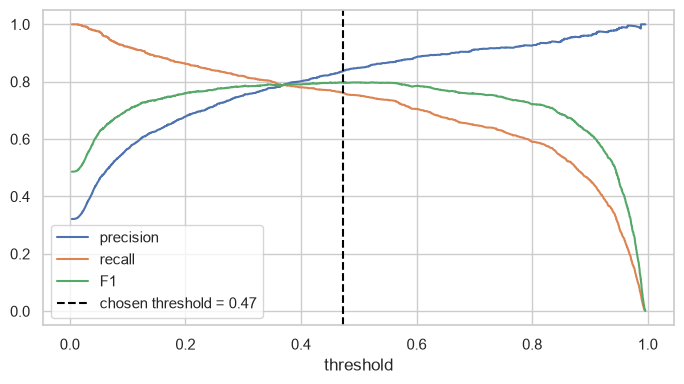

threshold=0.473  precision=0.838  recall=0.762  f1=0.798


In [22]:
oof = cross_val_predict(best_model, X_full_train, y_full_train, cv=cv, method="predict_proba", n_jobs=N_JOBS)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_full_train, oof)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_idx = int(np.argmax(f1[:-1]))
threshold = float(thresholds[best_idx])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.plot(thresholds, f1[:-1], label="F1")
plt.axvline(threshold, color="black", linestyle="--", label=f"chosen threshold = {threshold:.2f}")
plt.xlabel("threshold")
plt.legend()
plt.tight_layout()
plt.show()
print(f"threshold={threshold:.3f}  precision={precision[best_idx]:.3f}  recall={recall[best_idx]:.3f}  f1={f1[best_idx]:.3f}")

## 6. Final evaluation on the test set

Now, for the first time, the held-out 20% test set. The selected model is refitted on the whole 80% training
portion (GridSearchCV already did that with `refit=True`).

In [23]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= threshold).astype(int)

print(f"Test ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Test F1 @ {threshold:.2f}: {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["not dropout", "dropout"], digits=3))
print("Confusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, y_pred))

Test ROC AUC: 0.9427
Test F1 @ 0.47: 0.8306

              precision    recall  f1-score   support

 not dropout      0.910     0.938     0.924       601
     dropout      0.860     0.803     0.831       284

    accuracy                          0.895       885
   macro avg      0.885     0.871     0.877       885
weighted avg      0.894     0.895     0.894       885

Confusion matrix (rows = actual, cols = predicted):
[[564  37]
 [ 56 228]]


In [24]:
test_rows = []
for name, (_, s) in searches.items():
    test_rows.append({"model": name, "test_auc": roc_auc_score(y_test, s.best_estimator_.predict_proba(X_test)[:, 1])})
pd.DataFrame(test_rows).sort_values("test_auc", ascending=False).round(4)

,model,test_auc
3,XGBoost,0.9427
2,Random forest,0.9323
0,Logistic regression,0.9242
1,Decision tree,0.9169


The test AUC (0.943) is actually a bit higher than the cross-validated one (0.921). That's within normal split-to-split
variation (the CV folds themselves vary by about ±0.012), and the important part is that it isn't *lower*, so there's no sign
that the tuning overfitted.
I also show test AUC for all four tuned models just for reference. I did **not** use this table to choose
the model; that choice was made on cross-validation above.

### 6.1 What does the final model rely on?

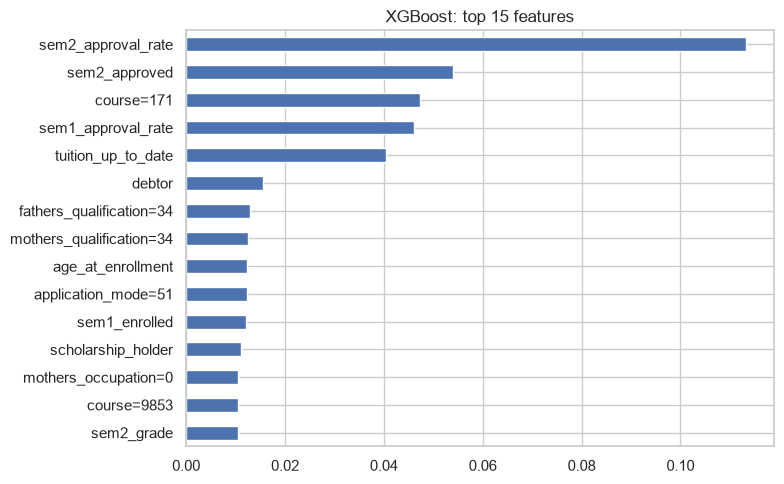

In [25]:
dv = best_model.named_steps["dictvectorizer"]
estimator = best_model.steps[-1][1]
if hasattr(estimator, "feature_importances_"):
    importance = pd.Series(estimator.feature_importances_, index=dv.get_feature_names_out())
else:
    importance = pd.Series(np.abs(estimator.coef_[0]), index=dv.get_feature_names_out())
top = importance.sort_values(ascending=False).head(15)
top.sort_values().plot.barh(figsize=(8, 5), color="#4C72B0")
plt.title(f"{best_name}: top 15 features")
plt.tight_layout()
plt.show()

The final model leans mostly on the approval rates, second-semester approved units and tuition status, which matches
the EDA and gives me some confidence it isn't relying on an artefact of the data. Two things I didn't expect:
course `171` (Animation and Multimedia Design) ranks high, and so do the "unknown" parental codes
(qualification `34` = unknown). Students whose parents' details are missing seem to differ from the rest, which would be
worth a closer look with the university.

## 7. Summary

- The binary dropout target is 32% positive, so I used ROC AUC as the main metric.
- I trained and tuned four models with 5-fold stratified CV: logistic regression, decision tree, random forest and XGBoost.
- The best model is used in `train.py` with the hyperparameters found here, plus the F1-optimal threshold.
- The strongest signals are first-year academic results and whether tuition fees are paid.

Next step: `train.py` reproduces the final model and saves it to `model.bin`, and `predict.py` serves it with FastAPI.